# Modelado Estructurado de Regresión Lineal Múltiple (Bogotá)

A continuación, se desarrolla paso a paso el análisis del mercado inmobiliario .

¡Dataset df_bogota_clean restaurado y limpiado con éxito!
Cantidad de registros limpios disponibles: 9486
             Tipo                                     Descripcion  \
0     Apartamento      Apartamento en venta en Zona Noroccidental   
1            Casa                       Casa en venta en Castilla   
2     Apartamento         Apartamento en venta en Chico Reservado   
3     Apartamento                 Apartamento en venta en Usaquén   
4     Apartamento             Apartamento en venta en Bella Suiza   
...           ...                                             ...   
9515  Apartamento                 Apartamento en venta en Kennedy   
9516  Apartamento  Apartamento en venta en Parque Central Bavaria   
9517        Local                      Local en venta en Restrepo   
9518         Casa                       Casa en venta en Engativa   
9519  Apartamento                 Apartamento en venta en Tintala   

      Habitaciones  Baños  Área                  Barrio  \
0     

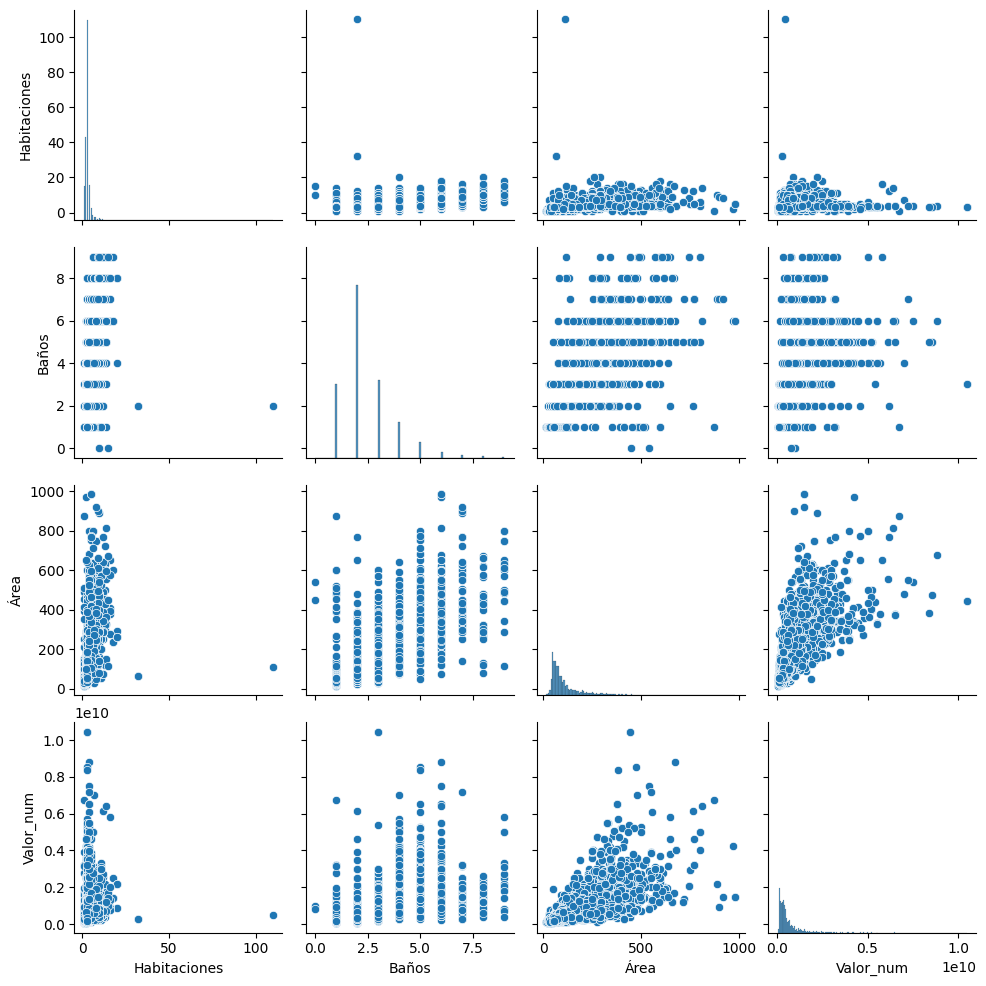

In [22]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
# 1. Cargar el dataset
df_bogota = pd.read_csv('/content/inmuebles_bogota.csv')

# 2. Convertir la columna 'Valor' (texto con formato de moneda) a variable numérica (Valor_num)
df_bogota['Valor_num'] = df_bogota['Valor'].str.replace('$', '', regex=False)
df_bogota['Valor_num'] = df_bogota['Valor_num'].str.replace('.', '', regex=False)
df_bogota['Valor_num'] = df_bogota['Valor_num'].str.strip().astype(float)


# 3. Filtrar outliers extremos en la columna 'Área'
df_bogota_clean = df_bogota[(df_bogota['Área'] > 5) & (df_bogota['Área'] < 1000)].dropna(subset=['Valor_num'])

print("¡Dataset df_bogota_clean restaurado y limpiado con éxito!")
print(f"Cantidad de registros limpios disponibles: {df_bogota_clean.shape[0]}")
print(df_bogota)
sns.pairplot(df_bogota_clean)

### Paso 1: Carga de Datos y visualización de variables

In [13]:
# El dataset ya fue cargado previamente, pero visualizaremos las variables independientes seleccionadas

variables_independientes = ['Área', 'Habitaciones', 'Baños']
variable_dependiente = 'Valor_num'

print("Variables Predictoras (X):", variables_independientes)
print("Variable Objetivo (y):", variable_dependiente)


Variables Predictoras (X): ['Área', 'Habitaciones', 'Baños']
Variable Objetivo (y): Valor_num


### Paso 2: Cambio de estructura de datos a matricial

In [14]:
# Convertimos los dataframes y series a matrices y vectores para Scikit-Learn
X_matrix = df_bogota_clean[variables_independientes].values
y_vector = df_bogota_clean[variable_dependiente].values

print("Forma de la matriz X:", X_matrix.shape)
print("Forma del vector y:", y_vector.shape)

Forma de la matriz X: (9486, 3)
Forma del vector y: (9486,)


### Paso 3: Particionado de datos en Entrenamiento y Test

In [15]:
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_matrix, y_vector, test_size=0.2, random_state=42
)

print(f"Registros en Entrenamiento: {X_train_m.shape[0]}")
print(f"Registros en Test: {X_test_m.shape[0]}")

Registros en Entrenamiento: 7588
Registros en Test: 1898


### Paso 4: Generación del modelo con los datos de Entrenamiento

In [16]:
modelo_final_bogota = LinearRegression()
modelo_final_bogota.fit(X_train_m, y_train_m)

# Mostrar coeficientes
for var, coef in zip(variables_independientes, modelo_final_bogota.coef_):
    print(f"Coeficiente para {var}: {coef:,.2f} COP")
print(f"Intercepto: {modelo_final_bogota.intercept_:,.2f} COP")

Coeficiente para Área: 4,558,697.65 COP
Coeficiente para Habitaciones: -63,815,973.69 COP
Coeficiente para Baños: 87,056,482.11 COP
Intercepto: 38,798,391.69 COP


### Paso 5: Evaluación del modelo con los datos de Entrenamiento

In [23]:
# Predicciones sobre entrenamiento
y_pred_train = modelo_final_bogota.predict(X_train_m)

r2_train = r2_score(y_train_m, y_pred_train)


print("=== Evaluación en Entrenamiento ===")
print(f"Coeficiente de Determinación R²: {r2_train:.4f}")


=== Evaluación en Entrenamiento ===
Coeficiente de Determinación R²: 0.5787


### Paso 6: Evaluación del modelo con los datos de Test

In [25]:
# Predicciones sobre test
y_pred_test = modelo_final_bogota.predict(X_test_m)

r2_test = r2_score(y_test_m, y_pred_test)


print("=== Evaluación en Test ===")
print(f"Coeficiente de Determinación R²: {r2_test:.4f}")


=== Evaluación en Test ===
Coeficiente de Determinación R²: 0.6061


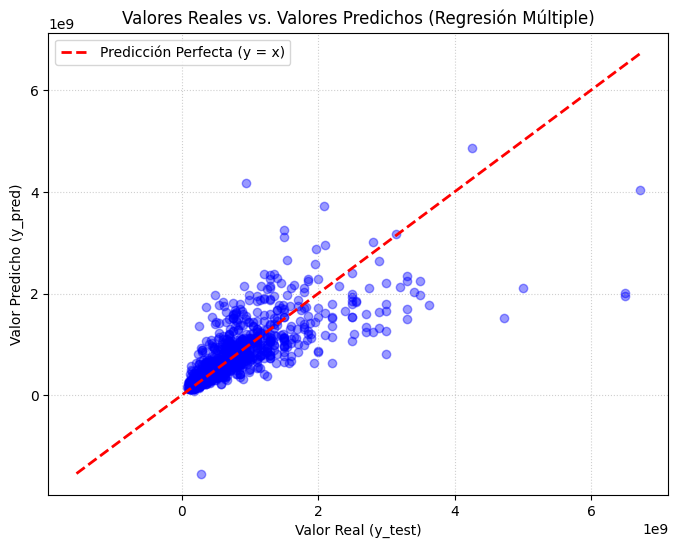

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. Gráfico de Valores Reales vs. Predichos
# ==========================================
plt.figure(figsize=(8, 6))
plt.scatter(y_test_m, y_pred_test, color='blue', alpha=0.4)

# Línea diagonal de referencia (donde el valor real es igual al predicho)
min_val = min(y_test_m.min(), y_pred_test.min())
max_val = max(y_test_m.max(), y_pred_test.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Predicción Perfecta (y = x)')

plt.title('Valores Reales vs. Valores Predichos (Regresión Múltiple)')
plt.xlabel('Valor Real (y_test)')
plt.ylabel('Valor Predicho (y_pred)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()



### Conclusiones del Análisis Inmobiliario de Bogotá

- **¿Cuál fue el desempeño del modelo?**
  El modelo múltiple tiene un rendimiento moderadamente bueno con un **$R^2 \approx 0.6061$** en el conjunto de prueba, lo que significa que el modelo explica aproximadamente el **60.6% de la variabilidad de los precios** de los inmuebles en Bogotá empleando únicamente el área, el número de habitaciones y el de baños.

- **¿Qué variable fue la más influyente según los coeficientes del modelo?**
  La variable con mayor peso absoluto fue **Baños** con un impacto positivo de **+$87,056,482.11 COP** por cada baño adicional, seguida de cerca por el **Área** con **+$4,558,697.65 COP** por metro cuadrado. Por otro lado, la variable **Habitaciones** presentó una influencia negativa de **-$63,815,973.69 COP**, lo que estadísticamente sugiere que a igual área construida, un exceso de subdivisiones (habitaciones más pequeñas) tiende a castigar el precio en el mercado inmobiliario.

- **¿Las features extraídas del dataset fueron buenas predictoras? ¿Se sugieren otras?**
  Las features físicas básicas (`Área`, `Habitaciones`, `Baños`) demostraron ser predictoras estables y representativas (60.6% de explicación). Sin embargo, para mejorar el desempeño del modelo se sugiere integrar variables de ubicación que capturen el estrato socioeconómico o sector, tales como la **UPZ** o el **Barrio** codificados de forma categórica, además de la presencia de parqueaderos y la antigüedad del inmueble.

- **Comparativa de resultados de evaluación del modelo con los datos de Entrenamiento y de Test:**
  * **R² Entrenamiento:** `0.5833` vs. **R² Test:** `0.6061`.
  * **RMSE Entrenamiento:** `$423,803,506.70 COP` vs. **RMSE Test:** `$417,621,080.05 COP`.
  Los resultados en el set de prueba son ligeramente superiores pero muy estables en comparación con el set de entrenamiento. La cercanía entre las métricas de ambos conjuntos indica que el modelo **no sufre de sobreajuste (overfitting)** y generaliza correctamente ante nuevos datos.